# **PM2.5 Trends and Convergence Across Selected Asian Countries**

## ***Project Overview***

This study analyzes long-term trends in annual average PM2.5 concentrations across China, Japan, South Korea, and India to evaluate whether PM2.5 gaps between China and the other nations have narrowed or expanded over time.
Using WHO country-level PM2.5 data, the project covers data cleaning, exploratory analysis, trend visualization, annual difference calculations, and statistical comparison of temporal shifts.



### *1. Data Loading*

The dataset originates from the WHO Global Health Observatory and contains country-level annual average PM2.5 concentration estimates.
This section loads and inspects the raw dataset prior to filtering or cleaning.


In [12]:
import pandas as pd

df_raw = pd.read_csv("../data/who_pm25_gho_raw.csv")

df_raw.head()

,IndicatorCode,Indicator,ValueType,ParentLocationCode,ParentLocation,Location type,SpatialDimValueCode,Location,Period type,Period,...,FactValueUoM,FactValueNumericLowPrefix,FactValueNumericLow,FactValueNumericHighPrefix,FactValueNumericHigh,Value,FactValueTranslationID,FactComments,Language,DateModified
0,SDGPM25,Concentrations of fine particulate matter (PM2.5),text,AMR,Americas,Country,CUB,Cuba,Year,2023,...,NaN,NaN,6.51,NaN,15.82,10.01 [6.51-15.82],NaN,NaN,EN,2026-05-08T04:00:00.000Z
1,SDGPM25,Concentrations of fine particulate matter (PM2.5),text,AMR,Americas,Country,CYM,Cayman Islands,Year,2023,...,NaN,NaN,4.73,NaN,21.55,10.04 [4.73-21.55],NaN,NaN,EN,2026-05-08T04:00:00.000Z
2,SDGPM25,Concentrations of fine particulate matter (PM2.5),text,AMR,Americas,Country,CYM,Cayman Islands,Year,2023,...,NaN,NaN,4.73,NaN,21.55,10.04 [4.73-21.55],NaN,NaN,EN,2026-05-08T04:00:00.000Z
3,SDGPM25,Concentrations of fine particulate matter (PM2.5),text,SEAR,South-East Asia,Country,MDV,Maldives,Year,2023,...,NaN,NaN,7.06,NaN,12.82,10.08 [7.06-12.82],NaN,NaN,EN,2026-05-08T04:00:00.000Z
4,SDGPM25,Concentrations of fine particulate matter (PM2.5),text,AMR,Americas,Country,USA,United States of America,Year,2023,...,NaN,NaN,9.81,NaN,10.41,10.08 [9.81-10.41],NaN,NaN,EN,2026-05-08T04:00:00.000Z


#### *1.1 Initial Dataset Inspection*
Prior to executing data cleaning or filtering procedures, this step evaluates the dataset dimensions, field names, data types, missing entries, and duplicate records. This preliminary inspection establishes the specific preprocessing workflow necessary for subsequent analysis.


In [13]:
print("Dataset shape:", df_raw.shape)

print("\nColumns:")
print(df_raw.columns.tolist())

print("\nData types:")
print(df_raw.dtypes)

print("\nMissing values:")
print(df_raw.isna().sum())

print("\nDuplicate rows:", df_raw.duplicated().sum())

Dataset shape: (14896, 34)

Columns:
['IndicatorCode', 'Indicator', 'ValueType', 'ParentLocationCode', 'ParentLocation', 'Location type', 'SpatialDimValueCode', 'Location', 'Period type', 'Period', 'IsLatestYear', 'Dim1 type', 'Dim1', 'Dim1ValueCode', 'Dim2 type', 'Dim2', 'Dim2ValueCode', 'Dim3 type', 'Dim3', 'Dim3ValueCode', 'DataSourceDimValueCode', 'DataSource', 'FactValueNumericPrefix', 'FactValueNumeric', 'FactValueUoM', 'FactValueNumericLowPrefix', 'FactValueNumericLow', 'FactValueNumericHighPrefix', 'FactValueNumericHigh', 'Value', 'FactValueTranslationID', 'FactComments', 'Language', 'DateModified']

Data types:
IndicatorCode                     str
Indicator                         str
ValueType                         str
ParentLocationCode                str
ParentLocation                    str
Location type                     str
SpatialDimValueCode               str
Location                          str
Period type                       str
Period                        

In [14]:
df_raw.sample(10, random_state=42)

,IndicatorCode,Indicator,ValueType,ParentLocationCode,ParentLocation,Location type,SpatialDimValueCode,Location,Period type,Period,...,FactValueUoM,FactValueNumericLowPrefix,FactValueNumericLow,FactValueNumericHighPrefix,FactValueNumericHigh,Value,FactValueTranslationID,FactComments,Language,DateModified
3546,SDGPM25,Concentrations of fine particulate matter (PM2.5),text,EMR,Eastern Mediterranean,Country,PSE,"occupied Palestinian territory, including east...",Year,2020,...,NaN,NaN,15.31,NaN,22.80,19.16 [15.31-22.80],NaN,NaN,EN,2026-05-08T04:00:00.000Z
9156,SDGPM25,Concentrations of fine particulate matter (PM2.5),text,AFR,Africa,Country,BEN,Benin,Year,2015,...,NaN,NaN,21.57,NaN,42.03,30.39 [21.57-42.03],NaN,NaN,EN,2026-05-08T04:00:00.000Z
4536,SDGPM25,Concentrations of fine particulate matter (PM2.5),text,EUR,Europe,Country,HRV,Croatia,Year,2019,...,NaN,NaN,14.86,NaN,18.50,16.63 [14.86-18.50],NaN,NaN,EN,2026-05-08T04:00:00.000Z
2267,SDGPM25,Concentrations of fine particulate matter (PM2.5),text,AMR,Americas,Country,ARG,Argentina,Year,2021,...,NaN,NaN,8.60,NaN,17.85,12.42 [8.60-17.85],NaN,NaN,EN,2026-05-08T04:00:00.000Z
13488,SDGPM25,Concentrations of fine particulate matter (PM2.5),text,AFR,Africa,Country,SLE,Sierra Leone,Year,2011,...,NaN,NaN,17.30,NaN,70.33,33.65 [17.30-70.33],NaN,NaN,EN,2026-05-08T04:00:00.000Z
14232,SDGPM25,Concentrations of fine particulate matter (PM2.5),text,AMR,Americas,Country,CUW,Curaçao,Year,2010,...,NaN,NaN,9.40,NaN,34.37,19.27 [9.40-34.37],NaN,NaN,EN,2026-05-08T04:00:00.000Z
9023,SDGPM25,Concentrations of fine particulate matter (PM2.5),text,AFR,Africa,Country,SSD,South Sudan,Year,2015,...,NaN,NaN,13.29,NaN,41.45,23.75 [13.29-41.45],NaN,NaN,EN,2026-05-08T04:00:00.000Z
9537,SDGPM25,Concentrations of fine particulate matter (PM2.5),text,EUR,Europe,Country,RUS,Russian Federation,Year,2015,...,NaN,NaN,7.24,NaN,11.31,8.94 [7.24-11.31],NaN,NaN,EN,2026-05-08T04:00:00.000Z
7719,SDGPM25,Concentrations of fine particulate matter (PM2.5),text,WPR,Western Pacific,Country,SGP,Singapore,Year,2016,...,NaN,NaN,14.67,NaN,17.93,16.08 [14.67-17.93],NaN,NaN,EN,2026-05-08T04:00:00.000Z
4793,SDGPM25,Concentrations of fine particulate matter (PM2.5),text,SEAR,South-East Asia,Country,BTN,Bhutan,Year,2019,...,NaN,NaN,23.45,NaN,29.85,26.74 [23.45-29.85],NaN,NaN,EN,2026-05-08T04:00:00.000Z


**Observations:**
- 14,896 rows × 34 columns (all countries, multiple years and residence-area types)
- 0 duplicate rows
- Key fields: `SpatialDimValueCode` (country), `Period` (year), `Dim1` (residence area), `FactValueNumeric` (PM2.5, µg/m³), plus lower/upper bounds
- `Value` column is text (value + interval), so `FactValueNumeric` is used instead
- Several columns (e.g., `Dim2`, `Dim3`, prefix columns) are empty/metadata and will be dropped

### *1.2 Key Column Check*
Inspect the dimension and value fields to identify the residence-area categories, confirm year coverage, and sanity-check the PM2.5 values before filtering.

In [15]:
# Inspect the fields relevant to our analysis
relevant_columns = [
    col for col in df_raw.columns
    if "Dim" in col or "Value" in col or "Fact" in col
]
print("Relevant columns:", relevant_columns)

# Residence-area breakdown (Dim1)
print("\nDim1 type:")
print(df_raw["Dim1 type"].value_counts(dropna=False))

print("\nDim1 values:")
print(df_raw["Dim1"].value_counts(dropna=False))

# Year coverage across the whole dataset
print("\nYear range:", df_raw["Period"].min(), "-", df_raw["Period"].max())

# PM2.5 values sanity check
print("\nPM2.5 (FactValueNumeric) summary:")

print(df_raw["FactValueNumeric"].describe())

Relevant columns: ['ValueType', 'SpatialDimValueCode', 'Dim1 type', 'Dim1', 'Dim1ValueCode', 'Dim2 type', 'Dim2', 'Dim2ValueCode', 'Dim3 type', 'Dim3', 'Dim3ValueCode', 'DataSourceDimValueCode', 'FactValueNumericPrefix', 'FactValueNumeric', 'FactValueUoM', 'FactValueNumericLowPrefix', 'FactValueNumericLow', 'FactValueNumericHighPrefix', 'FactValueNumericHigh', 'Value', 'FactValueTranslationID', 'FactComments']

Dim1 type:
Dim1 type
Residence Area Type    14896
Name: count, dtype: int64

Dim1 values:
Dim1
Total     3178
Rural     3052
Urban     3052
Towns     3024
Cities    2590
Name: count, dtype: int64

Year range: 2010 - 2023

PM2.5 (FactValueNumeric) summary:
count    14896.000000
mean        19.904027
std         12.886862
min          3.290000
25%         10.330000
50%         16.190000
75%         26.152500
max         86.210000
Name: FactValueNumeric, dtype: float64


### *1.3 Country Coverage Check*
Countries are selected by ISO3 code (CHN, JPN, KOR, IND) rather than name, since WHO lists South Korea as "Republic of Korea". This confirms each country's available year range.

In [16]:
# Check that each study country has data for the full period
country_codes = ["CHN", "JPN", "KOR", "IND"]

coverage = (
    df_raw[df_raw["SpatialDimValueCode"].isin(country_codes)]
    [["SpatialDimValueCode", "Location", "Period"]]
    .drop_duplicates()
    .groupby(["SpatialDimValueCode", "Location"])["Period"]
    .agg(["min", "max", "count"])
)
coverage

,,min,max,count
SpatialDimValueCode,Location,,,
CHN,China,2010,2023,14
IND,India,2010,2023,14
JPN,Japan,2010,2023,14
KOR,Republic of Korea,2010,2023,14


**Observations:**
- All four countries have complete coverage (2010–2023, 14 years each, no gaps)
- WHO data extends to 2023 (not 2022 as initially assumed); study period updated to 2010–2023
- South Korea is listed as "Republic of Korea" (KOR)

### *1.4 Data Preprocessing*
To prepare for the primary analytical pipeline, the dataset is restricted to China, Japan, South Korea, and India across the 2010 to 2023 timeframe. The filtering process isolates nationwide total residence-area figures, ensuring each target nation provides a single standardized annual PM2.5 metric. The resulting analytical subset retains the country code, country designation, reporting year, and quantitative PM2.5 concentration value.


In [17]:
# Select the four study countries
study_codes = ["CHN", "JPN", "KOR", "IND"]

df_clean = (
    df_raw[
        df_raw["SpatialDimValueCode"].isin(study_codes)
        & (df_raw["Dim1"] == "Total")
        & (df_raw["Period"].between(2010, 2023))
    ]
    [
        [
            "SpatialDimValueCode",
            "Location",
            "Period",
            "FactValueNumeric"
        ]
    ]
    .rename(
        columns={
            "SpatialDimValueCode": "CountryCode",
            "Location": "Country",
            "Period": "Year",
            "FactValueNumeric": "PM25"
        }
    )
    .sort_values(["Country", "Year"])
    .reset_index(drop=True)
)

df_clean.head()

,CountryCode,Country,Year,PM25
0,CHN,China,2010,59.71
1,CHN,China,2011,60.43
2,CHN,China,2012,57.32
3,CHN,China,2013,62.86
4,CHN,China,2014,54.00


In [18]:
print("Clean dataset shape:", df_clean.shape)

print("\nYear coverage by country:")
print(
    df_clean.groupby("Country")["Year"]
    .agg(["min", "max", "count"])
)

print("\nMissing values:")
print(df_clean.isna().sum())

print(
    "\nDuplicate country-year records:",
    df_clean.duplicated(subset=["Country", "Year"]).sum()
)

Clean dataset shape: (56, 4)

Year coverage by country:
                    min   max  count
Country                             
China              2010  2023     14
India              2010  2023     14
Japan              2010  2023     14
Republic of Korea  2010  2023     14

Missing values:
CountryCode    0
Country        0
Year           0
PM25           0
dtype: int64

Duplicate country-year records: 0


In [20]:
df_clean.to_csv(
    "../data/pm25_four_countries_2010_2023.csv",
    index=False
)

## 2. Exploratory Data Analysis (EDA)

This section explores annual PM2.5 concentrations across China, India,
Japan, and South Korea from 2010 to 2023.

The analysis examines descriptive statistics, long-term pollution trends,
year-over-year changes, and potential anomalies to identify patterns
and differences between the four countries.

### 2.1 Descriptive Statistics by Country

To establish a baseline comparison, descriptive statistics are calculated
for each country's annual PM2.5 concentrations.

These statistics include the mean, median, minimum, maximum, and standard
deviation, providing insight into typical pollution levels and variability
over the study period.

In [21]:
# Calculate descriptive statistics for each country
country_stats = (
    df_clean.groupby("Country")["PM25"]
    .agg(["count", "mean", "median", "min", "max", "std"])
    .round(2)
)

country_stats

,count,mean,median,min,max,std
Country,,,,,,
China,14,45.32,45.10,29.29,62.86,12.10
India,14,51.70,54.26,42.00,59.41,6.38
Japan,14,11.76,12.21,8.50,14.86,2.25
Republic of Korea,14,24.60,25.85,18.32,29.26,4.09


India exhibited the highest average PM2.5 concentration during the study period, while Japan had the lowest. China demonstrated the greatest variability, with a standard deviation of 12.10 µg/m³. These findings suggest substantial differences in pollution levels between the countries. Further analysis of annual trends is necessary to determine whether concentrations increased or decreased over time.

### 2.2 Annual PM2.5 Trends (2010–2023)

To examine long-term changes in air pollution, annual PM2.5
concentrations are visualized for China, India, Japan, and South Korea.

This comparison helps identify patterns of increasing or decreasing
pollution and differences in trends between the four countries.

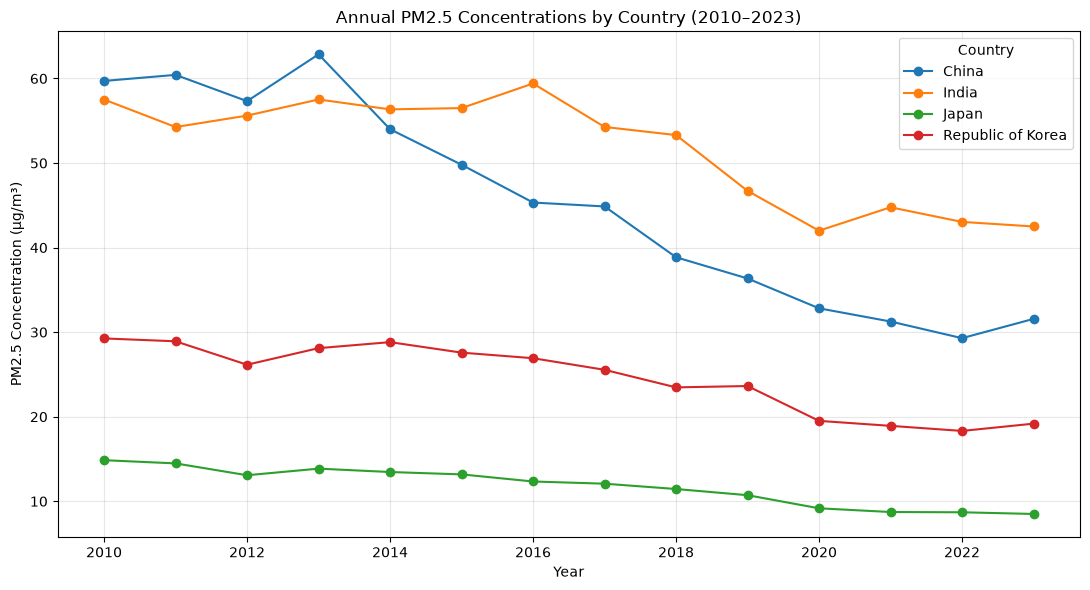

In [22]:
import matplotlib.pyplot as plt

# Create a figure for comparing annual PM2.5 trends
plt.figure(figsize=(11, 6))

# Plot annual PM2.5 concentrations for each country
for country, group in df_clean.groupby("Country"):
    plt.plot(
        group["Year"],
        group["PM25"],
        marker="o",
        label=country
    )

# Add descriptive labels and formatting
plt.title("Annual PM2.5 Concentrations by Country (2010–2023)")
plt.xlabel("Year")
plt.ylabel("PM2.5 Concentration (µg/m³)")
plt.legend(title="Country")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

Observations:
- China experienced a substantial decline in annual PM2.5 concentrations between 2010 and 2023, with the most pronounced reductions occurring after 2013.
- India maintained relatively high PM2.5 concentrations throughout the study period, although a downward trend became apparent in later years.
- Japan consistently exhibited the lowest concentrations, while South Korea demonstrated a gradual decline.
- China's PM2.5 concentrations initially exceeded India's, but India overtook China around 2014 and maintained higher concentrations thereafter.

Overall, the results suggest that all four countries experienced reductions in PM2.5 concentrations, although the magnitude and consistency of these changes differed.

In [23]:
# Sort observations chronologically within each country
df_changes = df_clean.sort_values(["Country", "Year"]).copy()

# Calculate the difference from the previous year
df_changes["AnnualChange"] = (
    df_changes.groupby("Country")["PM25"].diff()
)

# Display the results
df_changes[
    ["Country", "Year", "PM25", "AnnualChange"]
].head(20)

,Country,Year,PM25,AnnualChange
0,China,2010,59.71,NaN
1,China,2011,60.43,0.72
2,China,2012,57.32,-3.11
3,China,2013,62.86,5.54
4,China,2014,54.00,-8.86
5,China,2015,49.80,-4.20
6,China,2016,45.33,-4.47
7,China,2017,44.87,-0.46
8,China,2018,38.86,-6.01
9,China,2019,36.35,-2.51


### 2.4 Largest Annual Changes by Country

To identify periods of unusually large changes in air pollution,
the largest annual increase and decrease in PM2.5 concentration
are calculated for each country.

These results help identify potential anomalies and periods
of substantial improvement or deterioration.

In [24]:
# Find the largest annual increase and decrease for each country
annual_extremes = (
    df_changes.groupby("Country")["AnnualChange"]
    .agg(
        LargestIncrease="max",
        LargestDecrease="min"
    )
    .round(2)
)

annual_extremes

,LargestIncrease,LargestDecrease
Country,,
China,5.54,-8.86
India,2.91,-6.60
Japan,0.78,-1.55
Republic of Korea,1.96,-4.12


In [25]:
# Identify the years with the largest increases and decreases
valid_changes = df_changes.dropna(subset=["AnnualChange"])

largest_increases = valid_changes.loc[
    valid_changes.groupby("Country")["AnnualChange"].idxmax(),
    ["Country", "Year", "AnnualChange"]
]

largest_decreases = valid_changes.loc[
    valid_changes.groupby("Country")["AnnualChange"].idxmin(),
    ["Country", "Year", "AnnualChange"]
]

print("Largest annual increases:")
display(largest_increases)

print("Largest annual decreases:")
display(largest_decreases)

Largest annual increases:


,Country,Year,AnnualChange
3,China,2013,5.54
20,India,2016,2.91
31,Japan,2013,0.78
45,Republic of Korea,2013,1.96


Largest annual decreases:


,Country,Year,AnnualChange
4,China,2014,-8.86
23,India,2019,-6.60
38,Japan,2020,-1.55
52,Republic of Korea,2020,-4.12


**Observations:**

- China experienced the largest annual fluctuations among the four
  countries, including an increase of 5.54 µg/m³ in 2013 and a
  decrease of 8.86 µg/m³ in 2014.

- China, Japan, and South Korea each experienced their largest
  annual increases in 2013, although the magnitudes varied.

- Japan and South Korea experienced their largest annual decreases
  in 2020. These changes may warrant further investigation into
  regional or global factors affecting air pollution.

- Overall, the annual changes demonstrate that PM2.5 concentrations
  did not decrease uniformly. Instead, the countries experienced
  periods of improvement and occasional increases.

### 2.5 Overall PM2.5 Changes (2010–2023)

To compare long-term changes in air pollution, the absolute and
percentage changes in PM2.5 concentrations are calculated for
each country between 2010 and 2023.

Percentage changes allow comparisons between countries with
different initial pollution levels.

In [26]:
# Sort observations by country and year
df_sorted = df_clean.sort_values(["Country", "Year"])

# Extract the first and last PM2.5 observations for each country
overall_changes = (
    df_sorted.groupby("Country")["PM25"]
    .agg(
        PM25_2010="first",
        PM25_2023="last"
    )
)

# Calculate absolute change
overall_changes["AbsoluteChange"] = (
    overall_changes["PM25_2023"]
    - overall_changes["PM25_2010"]
)

# Calculate percentage change
overall_changes["PercentChange"] = (
    overall_changes["AbsoluteChange"]
    / overall_changes["PM25_2010"]
) * 100

overall_changes.round(2)

,PM25_2010,PM25_2023,AbsoluteChange,PercentChange
Country,,,,
China,59.71,31.57,-28.14,-47.13
India,57.51,42.50,-15.01,-26.10
Japan,14.86,8.50,-6.36,-42.80
Republic of Korea,29.26,19.18,-10.08,-34.45


### 2.6 Comparison of Overall PM2.5 Reductions

To visualize the relative improvement in air quality,
percentage reductions in PM2.5 concentrations between
2010 and 2023 are compared across the four countries.

This visualization highlights differences in the magnitude
of improvement relative to each country's initial
pollution concentration.

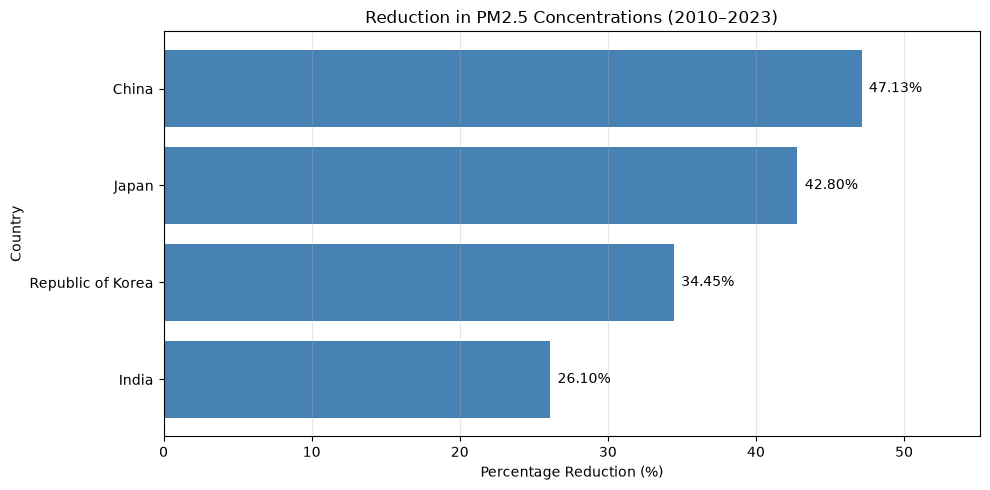

In [27]:
# Convert percentage changes into positive reduction values
percent_reductions = -overall_changes["PercentChange"]

# Sort countries by percentage reduction
percent_reductions = percent_reductions.sort_values()

# Create horizontal bar chart
plt.figure(figsize=(10, 5))

bars = plt.barh(
    percent_reductions.index,
    percent_reductions.values,
    color="steelblue"
)

# Add percentage labels to each bar
for bar in bars:
    width = bar.get_width()

    plt.text(
        width + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.2f}%",
        va="center"
    )

# Add labels and formatting
plt.title("Reduction in PM2.5 Concentrations (2010–2023)")
plt.xlabel("Percentage Reduction (%)")
plt.ylabel("Country")

plt.xlim(0, percent_reductions.max() + 8)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.show()

All four countries experienced reductions in annual average PM2.5 concentrations between 2010 and 2023. China demonstrated the largest relative reduction (47.13%), followed by Japan (42.80%), South Korea (34.45%), and India (26.10%). Although India's concentrations decreased, its percentage reduction was the smallest, indicating less relative improvement over the study period.

### 2.7 EDA Summary and Key Findings

1. Pollution differences: India had the highest mean PM2.5 concentration (51.70 µg/m³), while Japan had the lowest (11.76 µg/m³).



2. Long-term improvements: All four countries had lower PM2.5 concentrations in 2023 than in 2010.



3. China's variability: China exhibited the highest standard deviation (12.10 µg/m³) and largest single-year decline (−8.86 µg/m³ in 2014).



4. Notable annual changes: Japan and South Korea experienced their largest annual decreases in 2020.



5. Relative reductions: China achieved the greatest percentage reduction (47.13%), while India experienced the smallest (26.10%).